In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018Q4.csv.gz
/kaggle/input/datasets/wordsforthewise/lending-club/rejected_2007_to_2018Q4.csv.gz
/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv
/kaggle/input/datasets/wordsforthewise/lending-club/rejected_2007_to_2018q4.csv/rejected_2007_to_2018Q4.csv


In [2]:
file_path = "/kaggle/input/datasets/wordsforthewise/lending-club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv"

print("Data load ho raha hai, 1 minute lagega...")
# low_memory=False taaki columns ka data type theek se detect ho
df = pd.read_csv(file_path, low_memory=False)

print(f"Total Rows original data mein: {df.shape[0]:,}")
print(f"Total Columns original data mein: {df.shape[1]}")

# Dekhte hain loan_status column mein kya kya values hain
print("\nLoan Status values aur unka count:")
print(df['loan_status'].value_counts())

Data load ho raha hai, 1 minute lagega...
Total Rows original data mein: 2,260,701
Total Columns original data mein: 151

Loan Status values aur unka count:
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64


In [3]:
# 1. Sirf Fully Paid aur Charged Off loans rakhte hain
df_filtered = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()

# 2. Target column banate hain: Charged Off = 1 (Default), Fully Paid = 0
df_filtered['target'] = (df_filtered['loan_status'] == 'Charged Off').astype(int)

# 3. Memory aur speed ke liye 3,00,000 rows ka sample lete hain (random_state=42 taaki results reproducible rahein)
df_sample = df_filtered.sample(n=300000, random_state=42).copy()

print(f"Sample data ka shape: {df_sample.shape}")
print("\nTarget distribution (Percentages):")
print(df_sample['target'].value_counts(normalize=True) * 100)

Sample data ka shape: (300000, 152)

Target distribution (Percentages):
target
0    80.132667
1    19.867333
Name: proportion, dtype: float64


In [4]:
# 1. Ye columns loan approve hone ke BAAD ke hain (Data Leakage)
leakage_cols = [
    'funded_amnt', 'funded_amnt_inv', 'total_pymnt', 'total_pymnt_inv',
    'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
    'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
    'next_pymnt_d', 'last_credit_pull_d', 'debt_settlement_flag',
    'debt_settlement_flag_date', 'settlement_status', 'settlement_date',
    'settlement_amount', 'settlement_percentage', 'settlement_term',
    'out_prncp', 'out_prncp_inv', 'hardship_flag', 'hardship_type'
]

# 2. Ye columns faltu IDs ya Lambe text essays hain jo model ke kaam ke nahi
unwanted_cols = ['id', 'member_id', 'url', 'desc', 'loan_status']

# 3. Jo columns dataset mein hain, unhe filter karke drop karte hain
cols_to_drop = [c for c in leakage_cols + unwanted_cols if c in df_sample.columns]

df_clean = df_sample.drop(columns=cols_to_drop).copy()

print(f"Pehle total columns the: {df_sample.shape[1]}")
print(f"Leakage aur IDs hatane ke baad bache: {df_clean.shape[1]}")

Pehle total columns the: 152
Leakage aur IDs hatane ke baad bache: 123


In [5]:
# Har column ka missing value percentage calculate karte hain
missing_percent = (df_clean.isnull().sum() / len(df_clean)) * 100

# Jin columns mein 30% se zyada missing values hain unki list banate hain
cols_high_missing = missing_percent[missing_percent > 30].index.tolist()

print(f"30% se zyada missing values wale columns: {len(cols_high_missing)}")

# Unhe dataset se drop karte hain
df_clean = df_clean.drop(columns=cols_high_missing)

print(f"Ab bache total columns: {df_clean.shape[1]}")

30% se zyada missing values wale columns: 48
Ab bache total columns: 75


In [6]:
# 1. Term ko number mein convert karte hain (' 36 months' -> 36)
if 'term' in df_clean.columns:
    df_clean['term'] = df_clean['term'].astype(str).str.extract('(\d+)').astype(float)

# 2. Employment length ko numbers mein map karte hain
emp_map = {
    '< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3,
    '4 years': 4, '5 years': 5, '6 years': 6, '7 years': 7,
    '8 years': 8, '9 years': 9, '10+ years': 10
}
if 'emp_length' in df_clean.columns:
    df_clean['emp_length'] = df_clean['emp_length'].map(emp_map)

# 3. Interest rate agar text/string format mein hai toh number banate hain
if df_clean['int_rate'].dtype == 'object':
    df_clean['int_rate'] = df_clean['int_rate'].astype(str).str.replace('%', '').str.strip().astype(float)

# 4. Dates ko simple saal (Year) mein badalte hain (Feature Engineering)
# Jaise issue_d (Loan kis saal mila)
if 'issue_d' in df_clean.columns:
    df_clean['issue_year'] = pd.to_datetime(df_clean['issue_d'], format='%b-%Y').dt.year
    df_clean = df_clean.drop(columns=['issue_d'])

# earliest_cr_line (Bande ka pehla credit card/loan kis saal chalu hua tha)
if 'earliest_cr_line' in df_clean.columns:
    df_clean['earliest_cr_year'] = pd.to_datetime(df_clean['earliest_cr_line'], format='%b-%Y').dt.year
    df_clean = df_clean.drop(columns=['earliest_cr_line'])

# 5. Faltu text columns drop karte hain jinme hazaron alag text hain (jaise job title, zip code)
text_to_drop = ['emp_title', 'title', 'zip_code']
df_clean = df_clean.drop(columns=[c for c in text_to_drop if c in df_clean.columns])

print("Data Cleaning Complete!")
print(f"Abhi total columns: {df_clean.shape[1]}")

<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_48/3186720238.py:3: SyntaxWarning: invalid escape sequence '\d'
  df_clean['term'] = df_clean['term'].astype(str).str.extract('(\d+)').astype(float)


Data Cleaning Complete!
Abhi total columns: 72


In [7]:
from sklearn.model_selection import train_test_split

# 1. Features (X) aur Target (y) alag karte hain
X = df_clean.drop(columns=['target'])
y = df_clean['target']

# 2. 80% Training aur 20% Testing split
# stratify=y rakhte hain taaki train aur test dono mein exactly ~20% defaulters rahein
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print("\nTrain set default rate (%):")
print((y_train.value_counts(normalize=True) * 100).to_dict())
print("\nTest set default rate (%):")
print((y_test.value_counts(normalize=True) * 100).to_dict())

X_train shape: (240000, 71)
X_test shape:  (60000, 71)

Train set default rate (%):
{0: 80.1325, 1: 19.8675}

Test set default rate (%):
{0: 80.13333333333334, 1: 19.866666666666667}


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 1. Numeric aur Categorical columns alag pehchante hain
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

print(f"Numeric features count:     {len(num_cols)}")
print(f"Categorical features count: {len(cat_cols)}")
print("\nCategorical columns list:", cat_cols)

# 2. Numeric Transformer: Missing values ko median se fill karega
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# 3. Categorical Transformer: Missing ko 'missing' label dega, aur One-Hot Encode karega
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. ColumnTransformer mein combine karte hain
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

print("\nPreprocessor Pipeline ban chuki hai!")

Numeric features count:     59
Categorical features count: 10

Categorical columns list: ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'pymnt_plan', 'purpose', 'addr_state', 'initial_list_status', 'application_type', 'disbursement_method']

Preprocessor Pipeline ban chuki hai!


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
import numpy as np

# 1. Pipeline banate hain: Preprocessor + Logistic Regression
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

print("Baseline Logistic Regression model train ho raha hai (1-2 min lag sakte hain)...")
baseline_pipeline.fit(X_train, y_train)

# 2. Test set par default probabilities predict karte hain
y_pred_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

# 3. Benchmark Metrics calculate karte hain
baseline_auc = roc_auc_score(y_test, y_pred_proba)
baseline_pr_auc = average_precision_score(y_test, y_pred_proba)

print("\n--- Baseline Model Results (Logistic Regression) ---")
print(f"Test ROC-AUC Score: {baseline_auc:.4f}")
print(f"Test PR-AUC Score:  {baseline_pr_auc:.4f}")

Baseline Logistic Regression model train ho raha hai (1-2 min lag sakte hain)...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



--- Baseline Model Results (Logistic Regression) ---
Test ROC-AUC Score: 0.9388
Test PR-AUC Score:  0.7771


In [10]:
# One-hot encoded feature names nikalte hain
encoded_cat_names = baseline_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(encoded_cat_names)

# Coefficients nikal kar DataFrame banate hain
coefs = baseline_pipeline.named_steps['classifier'].coef_[0]
df_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefs,
    'Abs_Coef': np.abs(coefs)
}).sort_values(by='Abs_Coef', ascending=False)

print("Top 15 Most Influential Features (Inhe dhyan se dekho):")
print(df_importance.head(15)[['Feature', 'Coefficient']])

Top 15 Most Influential Features (Inhe dhyan se dekho):
                  Feature  Coefficient
16   last_fico_range_high    -0.016404
17    last_fico_range_low    -0.013419
9         fico_range_high     0.012854
8          fico_range_low     0.012686
1                    term     0.004879
2                int_rate     0.003146
51         pct_tl_nvr_dlq     0.003066
27                bc_util     0.002992
14             revol_util     0.002938
52       percent_bc_gt_75     0.002805
6                     dti     0.002787
35   mths_since_recent_bc    -0.002088
15              total_acc     0.001989
44          num_rev_accts     0.001399
32  mo_sin_rcnt_rev_tl_op    -0.001307


In [11]:
from sklearn.preprocessing import StandardScaler

# 1. Post-origination FICO columns ko X_train aur X_test se drop karte hain
leaky_fico_cols = ['last_fico_range_high', 'last_fico_range_low']
X_train_clean = X_train.drop(columns=[c for c in leaky_fico_cols if c in X_train.columns])
X_test_clean = X_test.drop(columns=[c for c in leaky_fico_cols if c in X_test.columns])

# 2. Numeric aur Categorical columns ko update karte hain
num_cols_clean = X_train_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols_clean = X_train_clean.select_dtypes(include=['object']).columns.tolist()

# 3. Numeric Transformer mein StandardScaler add karte hain taaki convergence warning na aaye
num_transformer_scaled = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer_clean = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_clean = ColumnTransformer(transformers=[
    ('num', num_transformer_scaled, num_cols_clean),
    ('cat', cat_transformer_clean, cat_cols_clean)
])

# 4. Leak-free Baseline Logistic Regression train karte hain
baseline_pipeline_clean = Pipeline(steps=[
    ('preprocessor', preprocessor_clean),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

print("Leak-free Baseline train ho raha hai...")
baseline_pipeline_clean.fit(X_train_clean, y_train)

# 5. Real Benchmark Scores calculate karte hain
y_pred_proba_clean = baseline_pipeline_clean.predict_proba(X_test_clean)[:, 1]
real_auc = roc_auc_score(y_test, y_pred_proba_clean)
real_pr_auc = average_precision_score(y_test, y_pred_proba_clean)

print("\n--- REAL Leak-Free Baseline Results ---")
print(f"Test ROC-AUC Score: {real_auc:.4f}")
print(f"Test PR-AUC Score:  {real_pr_auc:.4f}")

Leak-free Baseline train ho raha hai...

--- REAL Leak-Free Baseline Results ---
Test ROC-AUC Score: 0.7188
Test PR-AUC Score:  0.3818


In [12]:
import lightgbm as lgb
from scipy.stats import ks_2samp

# 1. KS-Statistic nikalne ke liye helper function
def calculate_ks(y_true, y_prob):
    # Defaulters (1) aur Non-Defaulters (0) ki predicted probabilities alag karte hain
    prob_default = y_prob[y_true == 1]
    prob_paid = y_prob[y_true == 0]
    ks_stat, _ = ks_2samp(prob_default, prob_paid)
    return ks_stat * 100  # Percentage mein

# 2. LightGBM Pipeline banate hain
# Note: Tree models ko StandardScaler ki zarurat nahi hoti, par same preprocessor use karne se comparison fair rehta hai
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    is_unbalance=True,      # 80/20 class imbalance handle karne ke liye
    random_state=42,
    n_jobs=-1,              # Saare CPU cores use karega fast training ke liye
    verbose=-1
)

lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_clean),
    ('classifier', lgb_model)
])

print("LightGBM model train ho raha hai (30-45 seconds lagenge)...")
lgb_pipeline.fit(X_train_clean, y_train)

# 3. Test set par probabilities predict karte hain
lgb_pred_proba = lgb_pipeline.predict_proba(X_test_clean)[:, 1]

# 4. Metrics calculate karte hain
lgb_auc = roc_auc_score(y_test, lgb_pred_proba)
lgb_pr_auc = average_precision_score(y_test, lgb_pred_proba)
lgb_gini = 2 * lgb_auc - 1
lgb_ks = calculate_ks(y_test.values, lgb_pred_proba)

# Baseline ke bhi Gini aur KS nikal lete hain comparison ke liye
base_gini = 2 * real_auc - 1
base_ks = calculate_ks(y_test.values, y_pred_proba_clean)

print("\n================ MODEL COMPARISON ================")
print(f"{'Metric':<15} | {'Logistic Reg':<15} | {'LightGBM':<15}")
print("-" * 50)
print(f"{'ROC-AUC':<15} | {real_auc:<15.4f} | {lgb_auc:<15.4f}")
print(f"{'PR-AUC':<15} | {real_pr_auc:<15.4f} | {lgb_pr_auc:<15.4f}")
print(f"{'Gini Index':<15} | {base_gini:<15.4f} | {lgb_gini:<15.4f}")
print(f"{'KS-Stat (%)':<15} | {base_ks:<15.2f}% | {lgb_ks:<15.2f}%")

LightGBM model train ho raha hai (30-45 seconds lagenge)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



================ MODEL COMPARISON ================
Metric          | Logistic Reg    | LightGBM       
--------------------------------------------------
ROC-AUC         | 0.7188          | 0.7282         
PR-AUC          | 0.3818          | 0.3989         
Gini Index      | 0.4375          | 0.4564         
KS-Stat (%)     | 32.08          % | 33.13          %


In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Business Cost Assumptions (in USD)
COST_FN = 10000  # Ek defaulter ko galti se approve karne ka nuksan (Principal loss)
COST_FP = 1500   # Ek achhe customer ko galti se reject karne ka nuksan (Lost interest)

# 0.10 se 0.90 tak thresholds check karte hain
thresholds = np.arange(0.10, 0.90, 0.05)
results = []

for thresh in thresholds:
    # Agar default probability >= thresh, toh Reject (1), warna Approve (0)
    y_pred_custom = (lgb_pred_proba >= thresh).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_custom).ravel()
    
    total_loss = (fn * COST_FN) + (fp * COST_FP)
    recall = tp / (tp + fn)
    approval_rate = (tn + fn) / len(y_test)
    
    results.append({
        'Threshold': round(thresh, 2),
        'Total_Loss ($M)': round(total_loss / 1e6, 2),
        'Defaulters_Caught (Recall %)': round(recall * 100, 1),
        'Loan_Approval_Rate (%)': round(approval_rate * 100, 1),
        'Missed_Defaults (FN)': fn,
        'Rejected_Good_Loans (FP)': fp
    })

df_thresh = pd.DataFrame(results)

# Sabse kam loss wala optimal threshold dhundhte hain
best_row = df_thresh.loc[df_thresh['Total_Loss ($M)'].idxmin()]
default_row = df_thresh[df_thresh['Threshold'] == 0.50].iloc[0]

print(df_thresh.to_string(index=False))
print("\n================ BUSINESS IMPACT SUMMARY ================")
print(f"Standard 0.50 Cutoff Loss : ${default_row['Total_Loss ($M)']} Million")
print(f"Optimal {best_row['Threshold']} Cutoff Loss  : ${best_row['Total_Loss ($M)']} Million")
savings = default_row['Total_Loss ($M)'] - best_row['Total_Loss ($M)']
print(f"Net Portfolio Savings     : ${savings:.2f} Million (on 60k test loans!)")

 Threshold  Total_Loss ($M)  Defaulters_Caught (Recall %)  Loan_Approval_Rate (%)  Missed_Defaults (FN)  Rejected_Good_Loans (FP)
      0.10            69.82                          99.7                     3.0                    38                     46295
      0.15            66.96                          99.0                     7.3                   122                     43825
      0.20            64.19                          97.6                    12.5                   289                     40866
      0.25            61.51                          95.3                    18.9                   556                     37303
      0.30            59.46                          92.1                    26.2                   947                     33328
      0.35            58.29                          87.6                    34.3                  1480                     28992
      0.40            58.76                          81.5                    43.0         

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


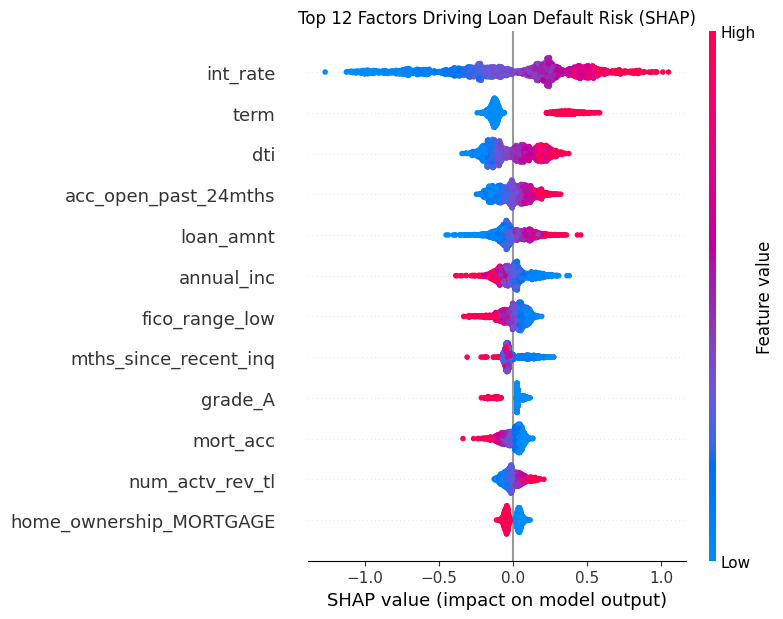


================ ADVERSE ACTION NOTICE (SAMPLE REJECTED LOAN) ================
Predicted Default Probability : 88.47% (Cutoff: 35.0%)
Decision                      : REJECTED

Top 3 Risk Factors (SHAP Reasons):
  1. int_rate (Risk Contribution: +0.726)
  2. term (Risk Contribution: +0.328)
  3. acc_open_past_24mths (Risk Contribution: +0.236)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [14]:
import shap
import matplotlib.pyplot as plt

# 1. Preprocessor se transformed test data aur feature names nikalte hain
preprocessor_fitted = lgb_pipeline.named_steps['preprocessor']
lgb_fitted = lgb_pipeline.named_steps['classifier']

# Feature names extract karte hain
encoded_cats = preprocessor_fitted.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols_clean)
feature_names = num_cols_clean + list(encoded_cats)

# Fast SHAP calculation ke liye test set ke 2,000 rows ka sample lete hain
X_test_sample = X_test_clean.iloc[:2000].copy()
X_test_transformed = preprocessor_fitted.transform(X_test_sample)

# 2. TreeExplainer initialize karke SHAP values nikalte hain
explainer = shap.TreeExplainer(lgb_fitted)
shap_values = explainer.shap_values(X_test_transformed)

# LightGBM binary classification mein agar list return ho toh class 1 (Default) select karte hain
if isinstance(shap_values, list):
    shap_vals_default = shap_values[1]
else:
    shap_vals_default = shap_values

# 3. Global Summary Plot banate hain
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_default, X_test_transformed, feature_names=feature_names, max_display=12, show=False)
plt.title("Top 12 Factors Driving Loan Default Risk (SHAP)")
plt.tight_layout()
plt.show()

# 4. Ek High-Risk Applicant ke liye Top 3 Adverse Action Reasons nikalte hain
sample_probs = lgb_pipeline.predict_proba(X_test_sample)[:, 1]
high_risk_idx = np.argmax(sample_probs)  # Sabse high default risk wala customer

customer_shap = pd.Series(shap_vals_default[high_risk_idx], index=feature_names)
top_3_reasons = customer_shap.sort_values(ascending=False).head(3)

print("\n================ ADVERSE ACTION NOTICE (SAMPLE REJECTED LOAN) ================")
print(f"Predicted Default Probability : {sample_probs[high_risk_idx]:.2%} (Cutoff: 35.0%)")
print("Decision                      : REJECTED")
print("\nTop 3 Risk Factors (SHAP Reasons):")
for i, (feat, val) in enumerate(top_3_reasons.items(), 1):
    print(f"  {i}. {feat} (Risk Contribution: +{val:.3f})")

In [15]:
import joblib

# Model aur zaroori metadata ko ek dictionary mein pack karte hain
model_artifact = {
    'pipeline': lgb_pipeline,
    'optimal_threshold': 0.35,
    'feature_names': feature_names,
    'num_cols': num_cols_clean,
    'cat_cols': cat_cols_clean,
    'default_values': X_train_clean.median(numeric_only=True).to_dict()
}

# File save karte hain
joblib.dump(model_artifact, 'credit_risk_model.joblib')

print("Model successfully save ho gaya: 'credit_risk_model.joblib'")

Model successfully save ho gaya: 'credit_risk_model.joblib'
